# Multiple Linear Regression on Hydrologic Data to predict Baseflow

## Setup

In [1]:
# Standard Library
from enum import StrEnum

# 3rd party
from pandas import read_csv, DataFrame, to_datetime, Timestamp
from seaborn import displot, scatterplot

DATA_PATH: str = "./data/RRCA_baseflow.csv"

class FlowCol(StrEnum):
    """
    Thanks Toby for this idea
    Lets you have auto-complete for the headers,
    less magic strings.
    """
    # Original Column Names
    DATE='Date',
    ID='Segment_id',
    X='x',
    Y='y',
    EVAPOTRANSPIRATION='Evapotranspiration',
    PRECIP='Precipitation',
    IRRIGATION_PUMPING='Irrigation_pumping',
    BASEFLOW='Observed' # The observed baseflow, I thought it made more sense to
                        # to name it BASEFLOW
    
    # Column Names Added In
    READABLE_DATE='readable_date',
    DAY='day',
    MONTH='month',
    YEAR='year'

baseflow_data: DataFrame = read_csv(DATA_PATH)

## Data Preparation

### Fix Dates

Adjust dates to be days since Jan 1st 1900, rather than previous value of days since Jan 1st 0000.

In [2]:
TEST_INDEX:int = 15586
date_before:int = baseflow_data[FlowCol.DATE][TEST_INDEX]

DATE_ADJUSTMENT: int = 693963 # value from proj instructions

baseflow_data[FlowCol.DATE] = (
    [date - DATE_ADJUSTMENT for date in baseflow_data[FlowCol.DATE]]
)

date_after:int = baseflow_data[FlowCol.DATE][TEST_INDEX]
assert(date_before - date_after == DATE_ADJUSTMENT)

Using professor's example to get more readable dates from the previous Date values

In [3]:
ORIGIN_DATE:Timestamp = Timestamp("1900-01-01")
baseflow_data[str(FlowCol.READABLE_DATE)] = to_datetime(
    baseflow_data[FlowCol.DATE].astype('int'), 
    unit='D', 
    origin=ORIGIN_DATE
)

baseflow_data[str(FlowCol.YEAR)] = (
    baseflow_data[FlowCol.READABLE_DATE].apply(lambda x:to_datetime(x).year)
)
baseflow_data[str(FlowCol.MONTH)] = (
    baseflow_data[FlowCol.READABLE_DATE].apply(lambda x:to_datetime(x).month)
)
baseflow_data[str(FlowCol.DAY)] = (
    baseflow_data[FlowCol.READABLE_DATE].apply(lambda x:to_datetime(x).day)
)

display(baseflow_data.head())

,Date,Segment_id,x,y,Evapotranspiration,Precipitation,Irrigation_pumping,Observed,readable_date,year,month,day
0,16769,144,1086190,14476800,0.59,18.99,0.0,0.145161,1945-11-30,1945,11,30
1,16800,144,1086190,14476800,0.97,29.63,0.0,0.445161,1945-12-31,1945,12,31
2,16828,144,1086190,14476800,1.34,29.63,0.0,1.332203,1946-01-28,1946,1,28
3,16859,144,1086190,14476800,1.79,29.63,0.0,2.932203,1946-02-28,1946,2,28
4,16889,144,1086190,14476800,8.23,29.63,0.0,3.728689,1946-03-30,1946,3,30


## Ideas to try next for making a better model

* only include gaging stations that have at least 10 years of monthly baseflow observations
* remove streamflow losses (non positive baseflow conditions)
* remove time periods that corresponde to zero baseflow
* use data from 1941-1989 for training and to fit the error distribution, and use data from 1990-2000 for validation.

Remove Streamflow Losses (non positive baseflow conditions) and Remove time periods that correspond to zero baseflow

In [4]:
baseflow_data = baseflow_data[baseflow_data[FlowCol.BASEFLOW] > 0.0]

Only include gaging stations that have at least 10 years of monthly baseflow observations

In [5]:
MIN_YRS = 10

# display(baseflow_data[baseflow_data[FlowCol.ID] == 144])
# display(baseflow_data[baseflow_data[FlowCol.ID] == 144][FlowCol.YEAR].unique())
# display(len(baseflow_data[baseflow_data[FlowCol.ID] == 144][FlowCol.YEAR].unique()))

print(f"Data size before: {baseflow_data.size}")

ids = baseflow_data[FlowCol.ID].unique()
for id in ids:
    if (len(baseflow_data[baseflow_data[FlowCol.ID] == id][FlowCol.YEAR].unique()) < MIN_YRS):
        baseflow_data = baseflow_data[baseflow_data[FlowCol.ID] != id]

print(f"Data size after: {baseflow_data.size}")

Data size before: 169380
Data size after: 163644


## Analysis

### Evapotranspiration with Baseflow

<Axes: xlabel='Evapotranspiration', ylabel='Observed'>

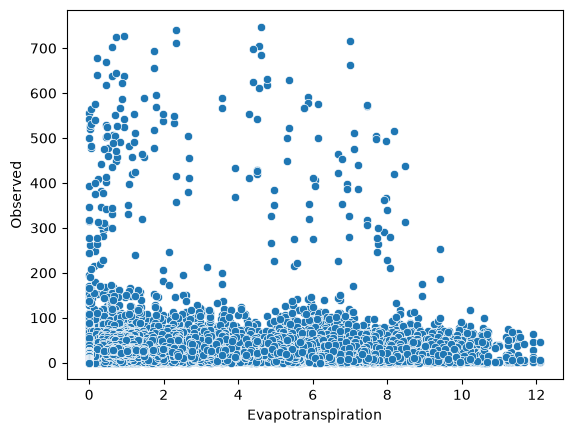

In [6]:
scatterplot(data=baseflow_data, x=FlowCol.EVAPOTRANSPIRATION, y=FlowCol.BASEFLOW)

### Precipitation with Baseflow

<Axes: xlabel='Precipitation', ylabel='Observed'>

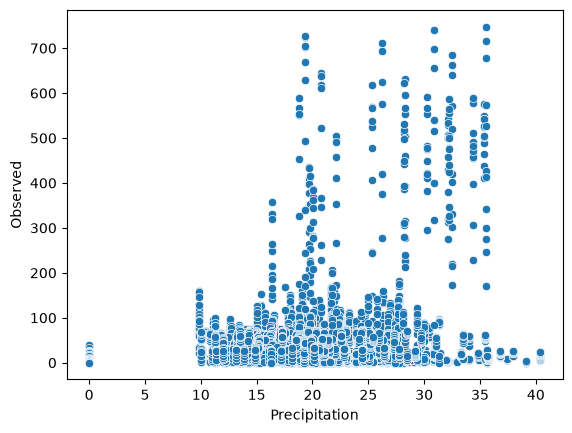

In [7]:
scatterplot(data=baseflow_data, x=FlowCol.PRECIP, y=FlowCol.BASEFLOW)

### Irrigation Pumping with Baseflow

<Axes: xlabel='Irrigation_pumping', ylabel='Observed'>

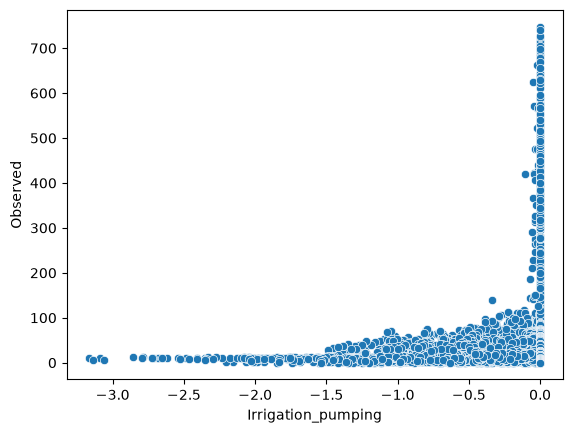

In [8]:
scatterplot(data=baseflow_data, x=FlowCol.IRRIGATION_PUMPING, y=FlowCol.BASEFLOW)

In [9]:
len(baseflow_data[FlowCol.ID].unique())


35